# SWIN timm XAI

In [1]:
import timm

model = timm.create_model(
    'swin_tiny_patch4_window7_224.ms_in22k_ft_in1k',
    pretrained=True,
    num_classes=4
)

C:\Users\user\anaconda3\envs\monai\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
import torch
import timm
import inspect

model.eval()

print("Model:", type(model).__name__)
print("timm version:", timm.__version__)

for name, module in model.named_modules():
    if "attn" in name.lower():
        print(
            f"\nName: {name}",
            f"\nClass: {type(module).__name__}",
            f"\nHeads: {getattr(module, 'num_heads', 'N/A')}",
            f"\nWindow size: {getattr(module, 'window_size', 'N/A')}",
            f"\nQKV: {type(module.qkv).__name__ if hasattr(module, 'qkv') else 'N/A'}"
        )

Model: SwinTransformer
timm version: 1.0.29

Name: layers.0.blocks.0.attn 
Class: WindowAttention 
Heads: 3 
Window size: (7, 7) 
QKV: Linear

Name: layers.0.blocks.0.attn.qkv 
Class: Linear 
Heads: N/A 
Window size: N/A 
QKV: N/A

Name: layers.0.blocks.0.attn.attn_drop 
Class: Dropout 
Heads: N/A 
Window size: N/A 
QKV: N/A

Name: layers.0.blocks.0.attn.proj 
Class: Linear 
Heads: N/A 
Window size: N/A 
QKV: N/A

Name: layers.0.blocks.0.attn.proj_drop 
Class: Dropout 
Heads: N/A 
Window size: N/A 
QKV: N/A

Name: layers.0.blocks.0.attn.softmax 
Class: Softmax 
Heads: N/A 
Window size: N/A 
QKV: N/A

Name: layers.0.blocks.1.attn 
Class: WindowAttention 
Heads: 3 
Window size: (7, 7) 
QKV: Linear

Name: layers.0.blocks.1.attn.qkv 
Class: Linear 
Heads: N/A 
Window size: N/A 
QKV: N/A

Name: layers.0.blocks.1.attn.attn_drop 
Class: Dropout 
Heads: N/A 
Window size: N/A 
QKV: N/A

Name: layers.0.blocks.1.attn.proj 
Class: Linear 
Heads: N/A 
Window size: N/A 
QKV: N/A

Name: layers.0.bloc

In [3]:
from timm.models.swin_transformer import WindowAttention

print(inspect.getsource(WindowAttention.forward))

    def forward(self, x: torch.Tensor, mask: Optional[torch.Tensor] = None) -> torch.Tensor:
        """Forward pass.

        Args:
            x: Input features with shape of (num_windows*B, N, C).
            mask: (0/-inf) mask with shape of (num_windows, Wh*Ww, Wh*Ww) or None.

        Returns:
            Output features with shape of (num_windows*B, N, C).
        """
        B_, N, C = x.shape
        qkv = self.qkv(x).reshape(B_, N, 3, self.num_heads, -1).permute(2, 0, 3, 1, 4)
        q, k, v = qkv.unbind(0)

        if self.fused_attn:
            attn_mask = self._get_rel_pos_bias()
            if mask is not None:
                num_win = mask.shape[0]
                mask = mask.view(1, num_win, 1, N, N).expand(B_ // num_win, -1, self.num_heads, -1, -1)
                attn_mask = attn_mask + mask.reshape(-1, self.num_heads, N, N)
            x = torch.nn.functional.scaled_dot_product_attention(
                q, k, v,
                attn_mask=attn_mask,
              

In [4]:
from timm.models.swin_transformer import SwinTransformerBlock
import inspect

print(inspect.getsource(SwinTransformerBlock.forward))

print("\n--- BLOCK ATTRIBUTES ---")

for stage_idx, stage in enumerate(model.layers):
    block = stage.blocks[0]

    print(f"\nStage {stage_idx + 1}")
    print("Input resolution:", getattr(block, "input_resolution", None))
    print("Window size:", getattr(block, "window_size", None))
    print("Shift size:", getattr(block, "shift_size", None))
    print("Attention fused:", block.attn.fused_attn)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        """Forward pass.

        Args:
            x: Input features with shape (B, H, W, C).

        Returns:
            Output features with shape (B, H, W, C).
        """
        B, H, W, C = x.shape
        x = x + self.drop_path1(self._attn(self.norm1(x)))
        x = x.reshape(B, -1, C)
        x = x + self.drop_path2(self.mlp(self.norm2(x)))
        x = x.reshape(B, H, W, C)
        return x


--- BLOCK ATTRIBUTES ---

Stage 1
Input resolution: (56, 56)
Window size: (7, 7)
Shift size: (0, 0)
Attention fused: False

Stage 2
Input resolution: (28, 28)
Window size: (7, 7)
Shift size: (0, 0)
Attention fused: False

Stage 3
Input resolution: (14, 14)
Window size: (7, 7)
Shift size: (0, 0)
Attention fused: False

Stage 4
Input resolution: (7, 7)
Window size: (7, 7)
Shift size: (0, 0)
Attention fused: False


In [5]:
for module in model.modules():
    if isinstance(module, WindowAttention):
        module.fused_attn = False

In [6]:
for stage_idx, stage in enumerate(model.layers):
    print(f"\nStage {stage_idx + 1}")

    for block_idx, block in enumerate(stage.blocks):
        print(
            f"Block {block_idx}: "
            f"Resolution={block.input_resolution}, "
            f"Window={block.window_size}, "
            f"Shift={block.shift_size}"
        )


Stage 1
Block 0: Resolution=(56, 56), Window=(7, 7), Shift=(0, 0)
Block 1: Resolution=(56, 56), Window=(7, 7), Shift=(3, 3)

Stage 2
Block 0: Resolution=(28, 28), Window=(7, 7), Shift=(0, 0)
Block 1: Resolution=(28, 28), Window=(7, 7), Shift=(3, 3)

Stage 3
Block 0: Resolution=(14, 14), Window=(7, 7), Shift=(0, 0)
Block 1: Resolution=(14, 14), Window=(7, 7), Shift=(3, 3)
Block 2: Resolution=(14, 14), Window=(7, 7), Shift=(0, 0)
Block 3: Resolution=(14, 14), Window=(7, 7), Shift=(3, 3)
Block 4: Resolution=(14, 14), Window=(7, 7), Shift=(0, 0)
Block 5: Resolution=(14, 14), Window=(7, 7), Shift=(3, 3)

Stage 4
Block 0: Resolution=(7, 7), Window=(7, 7), Shift=(0, 0)
Block 1: Resolution=(7, 7), Window=(7, 7), Shift=(0, 0)


In [7]:
print(inspect.getsource(type(model.layers[0].blocks[0])._attn))

    def _attn(self, x):
        B, H, W, C = x.shape

        # cyclic shift
        has_shift = any(self.shift_size)
        if has_shift:
            shifted_x = torch.roll(x, shifts=(-self.shift_size[0], -self.shift_size[1]), dims=(1, 2))
        else:
            shifted_x = x

        # pad for resolution not divisible by window size
        pad_h = (self.window_size[0] - H % self.window_size[0]) % self.window_size[0]
        pad_w = (self.window_size[1] - W % self.window_size[1]) % self.window_size[1]
        shifted_x = torch.nn.functional.pad(shifted_x, (0, 0, 0, pad_w, 0, pad_h))
        _, Hp, Wp, _ = shifted_x.shape

        # partition windows
        x_windows = window_partition(shifted_x, self.window_size)  # nW*B, window_size, window_size, C
        x_windows = x_windows.view(-1, self.window_area, C)  # nW*B, window_size*window_size, C

        # W-MSA/SW-MSA
        if getattr(self, 'dynamic_mask', False):
            attn_mask = self.get_attn_mask(shifted_x)
        el

In [8]:
for name, module in model.named_modules():
    if isinstance(module, WindowAttention):
        print(name, "fused_attn =", module.fused_attn)

layers.0.blocks.0.attn fused_attn = False
layers.0.blocks.1.attn fused_attn = False
layers.1.blocks.0.attn fused_attn = False
layers.1.blocks.1.attn fused_attn = False
layers.2.blocks.0.attn fused_attn = False
layers.2.blocks.1.attn fused_attn = False
layers.2.blocks.2.attn fused_attn = False
layers.2.blocks.3.attn fused_attn = False
layers.2.blocks.4.attn fused_attn = False
layers.2.blocks.5.attn fused_attn = False
layers.3.blocks.0.attn fused_attn = False
layers.3.blocks.1.attn fused_attn = False


## Load Dataset

In [9]:
from pathlib import Path
from collections import Counter
from monai.data import Dataset

import torch
import torch.nn as nn
import torch.nn.functional as F
import numpy as np
import matplotlib.pyplot as plt

from monai.transforms import (
    Compose,
    LoadImaged,
    EnsureChannelFirstd,
    Resized,
    ScaleIntensityd,
    EnsureTyped,
)

DATA_DIR = Path(r"..\..\data\brain-tumor-mri-classification\merged_dataset_v3\images")
assert DATA_DIR.exists(), f"Not found: {DATA_DIR.resolve()}"   # relative path depends on the notebook's working directory

class_names = ["glioma", "meningioma", "no_tumor", "pituitary"]
class_to_idx = {name: idx for idx, name in enumerate(class_names)}

def get_image_files(split):
    data = []
    for class_name in class_names:
        class_dir = DATA_DIR / split / class_name
        for image_path in sorted(class_dir.iterdir()):          # sorted = deterministic order
            if image_path.suffix.lower() in [".jpg", ".jpeg", ".png"]:
                data.append({"image": str(image_path), "label": class_to_idx[class_name]})
    return data

transforms = Compose([
    LoadImaged(keys=["image"]),
    EnsureChannelFirstd(keys=["image"]),
    Resized(keys=["image"], spatial_size=(224, 224)),
    ScaleIntensityd(keys=["image"]),
    EnsureTyped(keys=["image"]),
])

test_files = get_image_files("test")

test_dataset = Dataset(data=test_files, transform=transforms)

print("test:", len(test_files))
print("test per class:", Counter(class_names[d["label"]] for d in test_files))
print("sample:", tuple(test_dataset[0]["image"].shape))

test: 246
test per class: Counter({'glioma': 81, 'pituitary': 61, 'meningioma': 55, 'no_tumor': 49})
sample: (3, 224, 224)


## Load Model

In [10]:
import torch
import timm
import torch.nn.functional as F
import numpy as np
import matplotlib.pyplot as plt

from pathlib import Path
from collections import Counter

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

MODEL_PATH = Path("../../models/swin_tiny_using_timm.pt")

state_dict = torch.load(
    MODEL_PATH,
    map_location="cpu",
    weights_only=True
)

model.load_state_dict(state_dict, strict=True)

model = model.to(device)
model.eval()

print(model)

SwinTransformer(
  (patch_embed): PatchEmbed(
    (proj): Conv2d(3, 96, kernel_size=(4, 4), stride=(4, 4))
    (norm): LayerNorm((96,), eps=1e-05, elementwise_affine=True)
  )
  (layers): Sequential(
    (0): SwinTransformerStage(
      (downsample): Identity()
      (blocks): Sequential(
        (0): SwinTransformerBlock(
          (norm1): LayerNorm((96,), eps=1e-05, elementwise_affine=True)
          (attn): WindowAttention(
            (qkv): Linear(in_features=96, out_features=288, bias=True)
            (attn_drop): Dropout(p=0.0, inplace=False)
            (proj): Linear(in_features=96, out_features=96, bias=True)
            (proj_drop): Dropout(p=0.0, inplace=False)
            (softmax): Softmax(dim=-1)
          )
          (drop_path1): Identity()
          (norm2): LayerNorm((96,), eps=1e-05, elementwise_affine=True)
          (mlp): Mlp(
            (fc1): Linear(in_features=96, out_features=384, bias=True)
            (act): GELU(approximate='none')
            (drop1): 

## Apply Attention Rollout

In [12]:
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt
import numpy as np


def build_global_attention(probs, resolution, window_size, shift_size):
    """
    Convert window-based attention into a global spatial attention matrix.

    probs: [num_windows, num_heads, window_area, window_area]
    """
    H, W = resolution
    Wh, Ww = window_size
    Sh, Sw = shift_size

    assert H % Wh == 0 and W % Ww == 0

    device = probs.device
    attention = probs.mean(dim=1)

    global_attention = torch.zeros(
        H * W, H * W,
        device=device,
        dtype=attention.dtype
    )

    num_windows_w = W // Ww

    for window_idx in range(attention.shape[0]):
        window_row = window_idx // num_windows_w
        window_col = window_idx % num_windows_w

        rows = torch.arange(Wh, device=device) + window_row * Wh
        cols = torch.arange(Ww, device=device) + window_col * Ww

        rr, cc = torch.meshgrid(rows, cols, indexing="ij")

        # Reverse the cyclic shift to recover original coordinates.
        rr = (rr + Sh) % H
        cc = (cc + Sw) % W

        indices = (rr * W + cc).reshape(-1)

        global_attention[
            indices[:, None],
            indices[None, :]
        ] = attention[window_idx]

    return global_attention


def reverse_patch_merging(relevance, resolution):
    """
    Distribute each merged token's relevance equally
    across its four input tokens.
    """
    H, W = resolution

    relevance = relevance.reshape(H, W)

    previous = torch.zeros(
        H * 2, W * 2,
        device=relevance.device,
        dtype=relevance.dtype
    )

    previous[0::2, 0::2] = relevance * 0.25
    previous[1::2, 0::2] = relevance * 0.25
    previous[0::2, 1::2] = relevance * 0.25
    previous[1::2, 1::2] = relevance * 0.25

    return previous.reshape(-1)


def swin_attention_rollout(model, image_tensor):
    model.eval()

    captured = {}
    handles = []

    # Capture the actual attention probabilities from each block.
    for stage_idx, stage in enumerate(model.layers):
        for block_idx, block in enumerate(stage.blocks):

            attention_module = block.attn

            def hook(module, inputs, output, key):
                captured[key] = output.detach()

            key = (stage_idx, block_idx)

            handles.append(
                attention_module.softmax.register_forward_hook(
                    lambda module, inputs, output, key=key:
                        hook(module, inputs, output, key)
                )
            )

    try:
        with torch.no_grad():
            logits = model(image_tensor)

    finally:
        for handle in handles:
            handle.remove()

    # Feature-map resolutions for Swin-Tiny.
    resolutions = [
        (56, 56),
        (28, 28),
        (14, 14),
        (7, 7)
    ]

    # Start with uniform relevance over final-stage tokens.
    relevance = torch.ones(
        7 * 7,
        device=image_tensor.device
    ) / 49

    # Traverse stages and blocks in reverse order.
    for stage_idx in reversed(range(len(model.layers))):

        stage = model.layers[stage_idx]
        H, W = resolutions[stage_idx]

        for block_idx in reversed(range(len(stage.blocks))):

            block = stage.blocks[block_idx]
            key = (stage_idx, block_idx)

            probabilities = captured[key]

            attention = build_global_attention(
                probabilities,
                resolution=(H, W),
                window_size=block.window_size,
                shift_size=block.shift_size
            )

            # Add residual connection and normalize.
            identity = torch.eye(
                H * W,
                device=attention.device,
                dtype=attention.dtype
            )

            attention = attention + identity
            attention = attention / attention.sum(
                dim=-1,
                keepdim=True
            )

            # Propagate relevance backward.
            relevance = attention.T @ relevance

        # Reverse patch merging between stages.
        if stage_idx > 0:
            relevance = reverse_patch_merging(
                relevance,
                resolution=resolutions[stage_idx]
            )

    # Convert the final 56x56 relevance map to 224x224.
    relevance_map = relevance.reshape(1, 1, 56, 56)

    relevance_map = F.interpolate(
        relevance_map,
        size=(224, 224),
        mode="bilinear",
        align_corners=False
    )

    relevance_map = relevance_map.squeeze().cpu().numpy()

    # Normalize for visualization.
    relevance_map -= relevance_map.min()
    relevance_map /= relevance_map.max() + 1e-8

    predicted_class = logits.argmax(dim=1).item()

    return predicted_class, relevance_map

glioma | rf_test_glioma_725.jpg


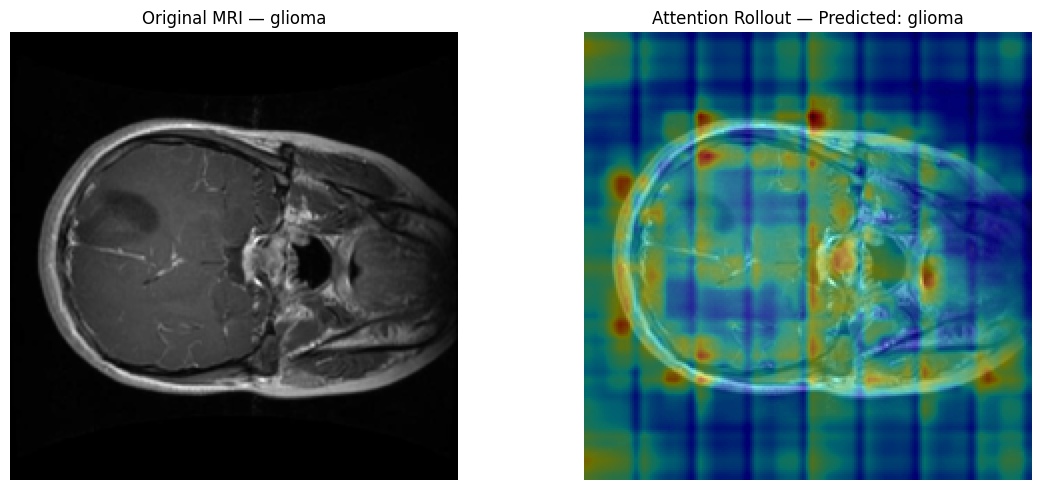

meningioma | rf_test_meningioma_491.jpg


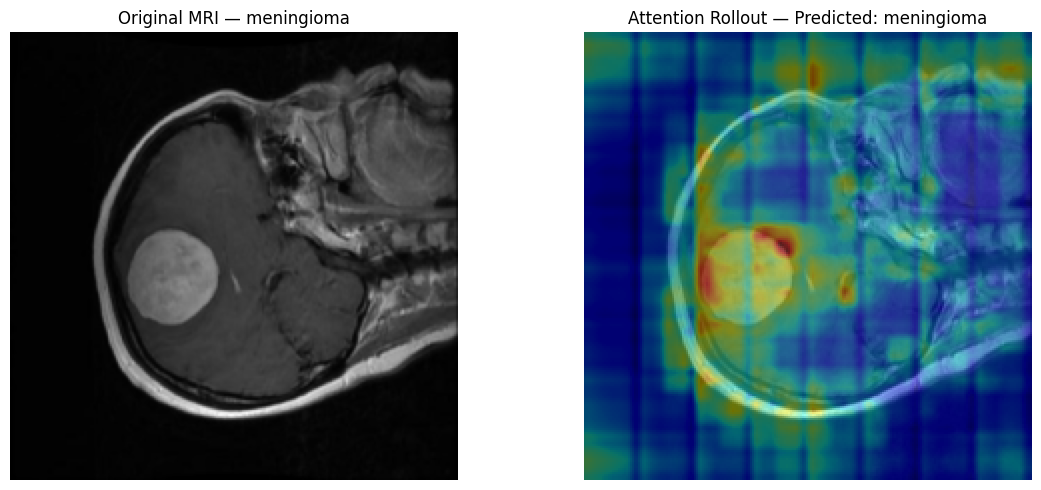

no_tumor | rf_test_no_tumor_435.jpg


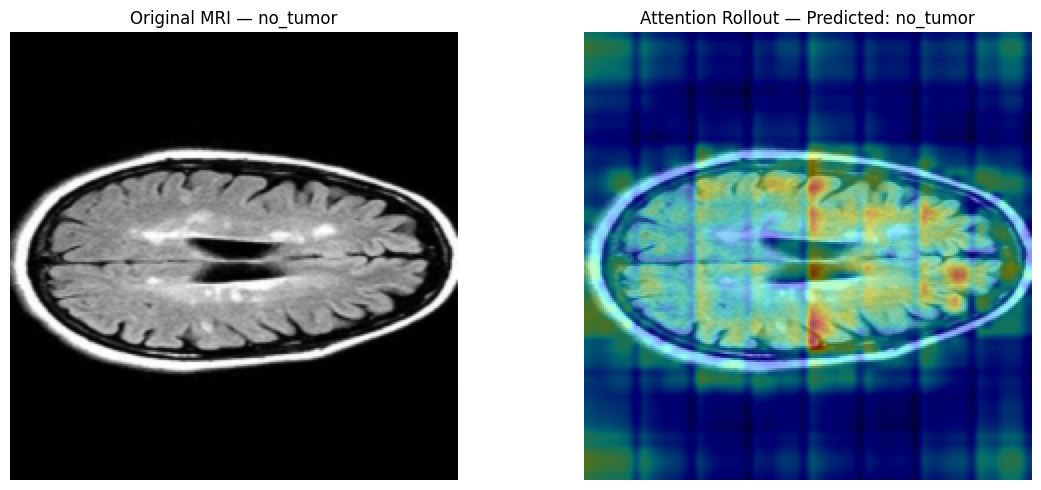

pituitary | rf_test_pituitary_550.jpg


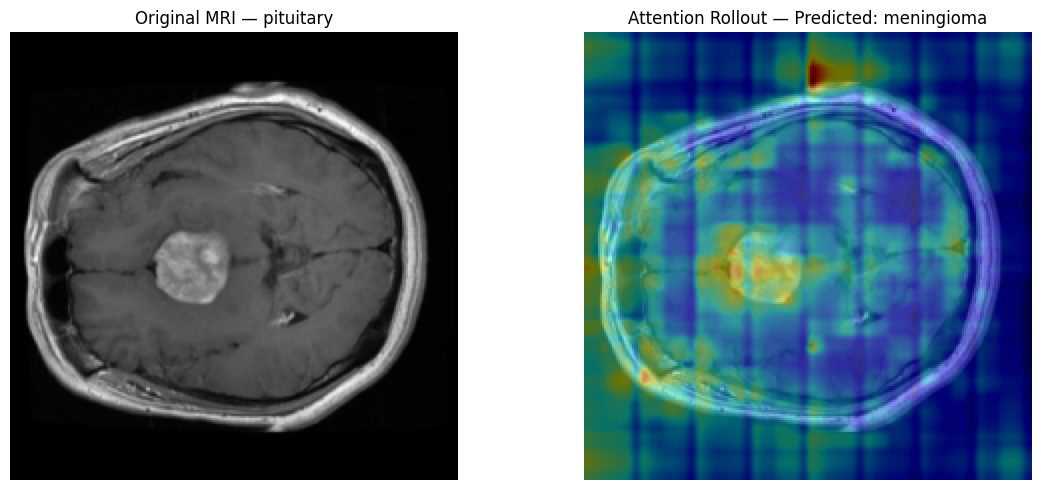

In [14]:
class_names = ["glioma", "meningioma", "no_tumor", "pituitary"]

by_class = {}

for idx, data in sorted(
    enumerate(test_files),
    key=lambda item: item[1]["image"]
):
    by_class.setdefault(data["label"], idx)


for class_idx in sorted(by_class):

    image_idx = by_class[class_idx]
    sample = test_dataset[image_idx]

    # Extract image and add batch dimension.
    image_tensor = sample["image"].unsqueeze(0).to(device)

    print(
        f"{class_names[class_idx]} | "
        f"{Path(test_files[image_idx]['image']).name}"
    )

    predicted_class, attention_map = swin_attention_rollout(
        model,
        image_tensor
    )

    original_image = (
        image_tensor[0]
        .permute(1, 2, 0)
        .cpu()
        .numpy()
    )

    plt.figure(figsize=(12, 5))

    plt.subplot(1, 2, 1)
    plt.imshow(original_image)
    plt.title(f"Original MRI — {class_names[class_idx]}")
    plt.axis("off")

    plt.subplot(1, 2, 2)
    plt.imshow(original_image)
    plt.imshow(attention_map, cmap="jet", alpha=0.45)
    plt.title(
        f"Attention Rollout — Predicted: {class_names[predicted_class]}"
    )
    plt.axis("off")

    plt.tight_layout()
    plt.show()